# Screening OB units: cell bodies outside the glomerular layer

This extends `6_mt_classifier.ipynb` with a screen for the units we don't want: axonal or dendritic spikes, and units in
the glomerular layer (GL). It follows `reference/ob_unit_screening_spec.md`, but uses **only the signal**. Histology and
depth are left out for now, so the spec's primary GL rule (distance to the GL/EPL border) isn't applied. Scores come
from `sniff-raster-python/ob_screening.py` (`E:/cbm-odor/sniff/unit_screening.csv`), with every threshold in
`ob_screening_config.json`. Those thresholds were fixed before the run, and none of them uses spatial or behavioral
tuning.

Every unit gets one of three labels:

- **exclude**: a signal on one wire that is also small (`confined_small`), or an OSN-terminal signature
  (`osn_terminal_like`: an axonal waveform, early sniff excitation and no sniff-locked dip)
- **ambiguous**: a positive or positive-leading spike (`positive_waveform`, `triphasic_waveform`), an outlier in width
  against the best-isolated units (`width_outlier`), a GL-like LFP on its tetrode (`lfp_gl_like`), small and bursty
  like a juxtaglomerular cell (`jg_like`), or too few spikes
- **include**: everything else

`screen_reason` lists every criterion a unit failed.

Three rules from the spec shape this:

- **Single-unit quality is reported, not used.** Refractory violations, isolation distance and L-ratio, amplitude
  drift, and spikes that look the same on all four wires (`uniform_wires`) are in `quality_flags` and don't change the
  label. Most OB clusters are multi-unit, and the spec's 1% refractory
  rule would leave about 7% of units.
- **Polarity only makes a unit ambiguous.** The spec excludes positive spikes as axonal or dendritic. Here 44% of OB
  units are positive, though, and so are about 40% of CA1 units in the same recordings (see the polarity section).
- **Early firing never counts against a unit.** Tufted cells fire early, so sniff timing only enters the OSN rule, and
  only together with an axonal waveform and no sniff-locked dip.
- **The M/T labels stay separate.** They're joined unchanged as `mt_*` columns, so a unit can be `tufted` and also be
  `exclude`.

Use `include` units for main results, and `include` + `ambiguous` as the sensitivity check.

In [1]:
import sys
sys.path.insert(0, 'sniff-raster-python')  # the analysis modules live there
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import ob_screening as scr

OUT = scr.OUT_DIR
d = pd.read_csv(OUT + 'unit_screening.csv', dtype={'mouse': str, 'session': str})
d[['screen_reason', 'quality_flags']] = d[['screen_reason', 'quality_flags']].fillna('')
lfp = pd.read_csv(OUT + 'unit_screening_lfp.csv', dtype={'mouse': str, 'session': str})
z = np.load(OUT + 'unit_screening.npz')
assert (z['cluster'] == d['cluster']).all() and (z['session'] == d['session']).all()
cfg = json.load(open(OUT + 'unit_screening_config.json'))
s0, wv, gl = cfg['stage0'], cfg['waveform'], cfg['gl_signatures']

LABELS = ['include', 'ambiguous', 'exclude']
LABEL_COLORS = dict(include='#0ca30c', ambiguous='#fab219', exclude='#d03b3b')  # status palette
POLARITY_COLORS = dict(negative='#2a78d6', positive='#eb6834', triphasic='#1baf7a')
MT_COLORS = {'tufted': 'tab:blue', 'mitral': 'tab:red', 'other': 'tab:gray'}  # as in 6_mt_classifier
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '0.92', 'grid.linewidth': 0.6, 'axes.axisbelow': True})
print(f"{len(d)} OB units from {d.groupby(['mouse', 'session']).ngroups} sessions, "
      f"{lfp.groupby(['mouse', 'session']).ngroups} with LFP")
print(d['screen_label'].value_counts().reindex(LABELS).to_string())

1968 OB units from 119 sessions, 124 with LFP
screen_label
include       776
ambiguous    1136
exclude        56


## Units removed by each criterion

Two counts per criterion: units that fail it, and units that fail *only* it, which is what that criterion costs on
its own. The single-unit quality flags at the bottom don't change the label.

In [2]:
def criterion_table(d):
    labelled = list(scr.EXCLUDE) + list(scr.AMBIGUOUS)
    fails = d[[f'fail_{c}' for c in labelled]].to_numpy()
    rows = []
    for i, c in enumerate(labelled):
        rows.append(dict(criterion=c, effect='exclude' if c in scr.EXCLUDE else 'ambiguous',
                         n_fail=int(fails[:, i].sum()),
                         n_only=int((fails[:, i] & (fails.sum(1) == 1)).sum())))
    for c in scr.REPORT:
        rows.append(dict(criterion=c, effect='reported only', n_fail=int(d[f'fail_{c}'].sum()), n_only=np.nan))
    t = pd.DataFrame(rows)
    t['pct_fail'] = (100 * t['n_fail'] / len(d)).round(1)
    return t

criterion_table(d)

,criterion,effect,n_fail,n_only,pct_fail
0,confined_small,exclude,1,0.0,0.1
1,osn_terminal_like,exclude,55,0.0,2.8
2,positive_waveform,ambiguous,873,640.0,44.4
3,triphasic_waveform,ambiguous,282,239.0,14.3
4,width_outlier,ambiguous,196,9.0,10.0
5,lfp_gl_like,ambiguous,4,1.0,0.2
6,jg_like,ambiguous,84,25.0,4.3
7,few_spikes,ambiguous,0,0.0,0.0
8,no_waveform,ambiguous,0,0.0,0.0
9,isi_violations,reported only,1823,NaN,92.6


In [3]:
pd.crosstab(d['mouse'], d['screen_label'], margins=True)[LABELS + ['All']]

screen_label,include,ambiguous,exclude,All
mouse,,,,
9000,102,131,6,239
9002,87,133,9,229
9003,69,98,3,170
9005,102,171,7,280
9006,131,308,20,459
9007,58,74,2,134
9008,122,136,8,266
9009,105,85,1,191
All,776,1136,56,1968


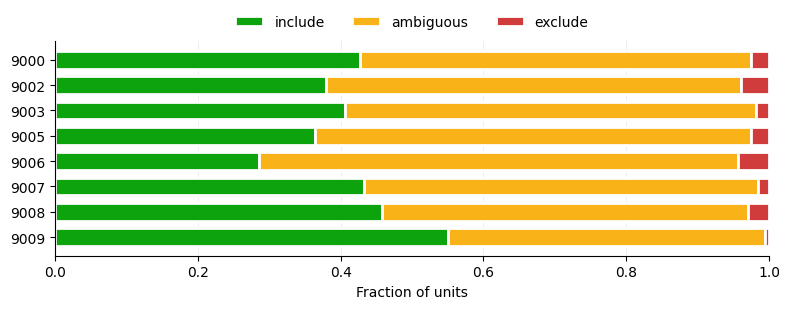

In [4]:
t = pd.crosstab(d['mouse'], d['screen_label'], normalize='index')[LABELS]
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(len(t))
for lab in LABELS:
    ax.barh(t.index, t[lab], left=left, color=LABEL_COLORS[lab], label=lab, height=0.7, edgecolor='white', lw=2)
    left += t[lab].to_numpy()
ax.set(xlabel='Fraction of units', xlim=(0, 1))
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1))
fig.tight_layout()

## Stage 0: single-unit quality (reported only)

The dashed lines are the config's thresholds. Refractory violations are the fraction of ISIs under 1.5 ms. Isolation
distance and L-ratio come from the Kilosort PC features on the unit's four wires, against every other cluster on the
same wires.

       isi_violation  isolation_distance  l_ratio
group                                            
good           0.011              41.239    0.026
mua            0.032              28.348    0.190


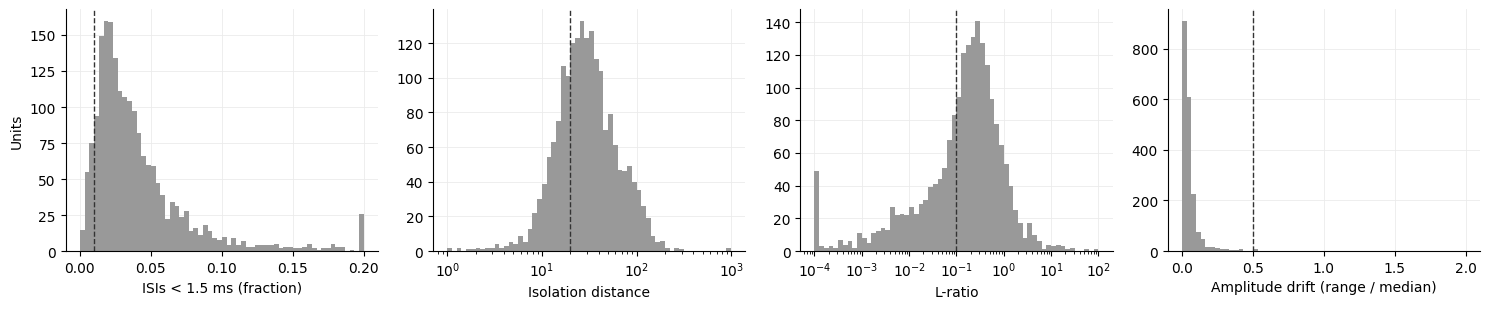

In [5]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.2))
spec = [('isi_violation', 'ISIs < 1.5 ms (fraction)', np.linspace(0, 0.2, 61), s0['max_isi_violation'], False),
        ('isolation_distance', 'Isolation distance', np.logspace(0, 3, 61), s0['min_isolation_distance'], True),
        ('l_ratio', 'L-ratio', np.logspace(-4, 2, 61), s0['max_l_ratio'], True),
        ('amplitude_drift', 'Amplitude drift (range / median)', np.linspace(0, 2, 61), s0['max_amplitude_drift'], False)]
for ax, (col, lab, bins, th, logx) in zip(axs, spec):
    ax.hist(d[col].dropna().clip(bins[0], bins[-1]), bins, color='0.6')
    ax.axvline(th, color='0.2', ls='--', lw=1)
    ax.set(xlabel=lab, xscale='log' if logx else 'linear')
axs[0].set_ylabel('Units')
fig.tight_layout()
print(d.groupby('group')[['isi_violation', 'isolation_distance', 'l_ratio']].median().round(3))

## Stage A: cell body vs axon or dendrite

The mean waveform comes from the raw recording (up to 500 spikes, 300-6000 Hz) on the four wires of the tetrode with
the largest spike. Measured on the peak wire:

- `pos_ratio`: the largest positive deflection / the trough. Above 1, the spike is mostly positive: `positive`.
- `pre_ratio`: the positive peak before the trough / the trough. Above 0.5, a positive phase leads the spike:
  `triphasic`.
- `trough_to_peak_ms` and `half_width_ms`, scored against the internal reference: the best-isolated negative units
  (SNR >= 2, < 2% refractory violations, isolation distance >= 20, L-ratio <= 0.1). There are 31; mouse 9002 has
  enough for its own reference, and the rest share a pooled one.

Kilosort's template (unwhitened) gives an independent `template_pos_ratio`, as a check on the mean waveform.

reference_pool
all     1739
9002     229


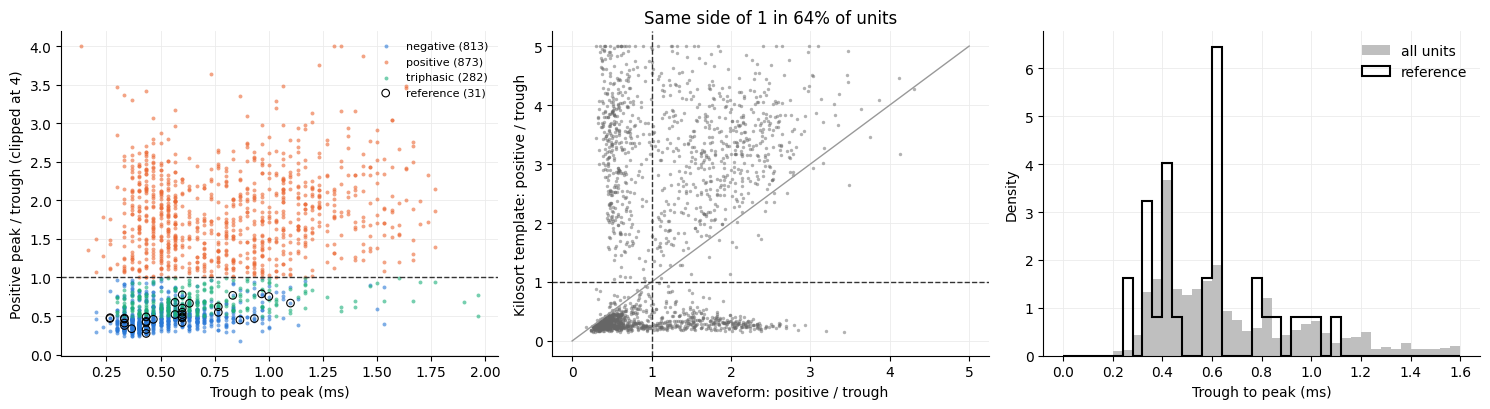

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axs[0]
for p, c in POLARITY_COLORS.items():
    s = d['polarity'] == p
    ax.scatter(d.loc[s, 'trough_to_peak_ms'], d.loc[s, 'pos_ratio'].clip(0, 4), s=8, c=c, alpha=0.6,
               label=f'{p} ({s.sum()})', lw=0)
r = d['reference_unit']
ax.scatter(d.loc[r, 'trough_to_peak_ms'], d.loc[r, 'pos_ratio'], s=30, facecolor='none', edgecolor='k', lw=0.8,
           label=f'reference ({r.sum()})')
ax.axhline(wv['max_positive_ratio'], color='0.2', ls='--', lw=1)
ax.set(xlabel='Trough to peak (ms)', ylabel='Positive peak / trough (clipped at 4)')
ax.legend(frameon=False, fontsize=8)

ax = axs[1]
ax.scatter(d['pos_ratio'].clip(0, 5), d['template_pos_ratio'].clip(0, 5), s=6, c='0.4', alpha=0.5, lw=0)
ax.plot([0, 5], [0, 5], color='0.6', lw=1)
ax.axhline(1, color='0.2', ls='--', lw=1)
ax.axvline(1, color='0.2', ls='--', lw=1)
agree = ((d['pos_ratio'] > 1) == (d['template_pos_ratio'] > 1))[d['polarity'].notna()].mean()
ax.set(xlabel='Mean waveform: positive / trough', ylabel='Kilosort template: positive / trough',
       title=f'Same side of 1 in {agree:.0%} of units')

ax = axs[2]
bins = np.linspace(0, 1.6, 41)
ax.hist(d['trough_to_peak_ms'].dropna(), bins, color='0.75', label='all units', density=True)
ax.hist(d.loc[r, 'trough_to_peak_ms'], bins, histtype='step', color='k', lw=1.5, label='reference', density=True)
ax.set(xlabel='Trough to peak (ms)', ylabel='Density')
ax.legend(frameon=False)
fig.tight_layout()
print(d['reference_pool'].value_counts().to_string())

Mean waveforms on the peak wire, normalized to the trough, for 30 randomly chosen units of each polarity class.

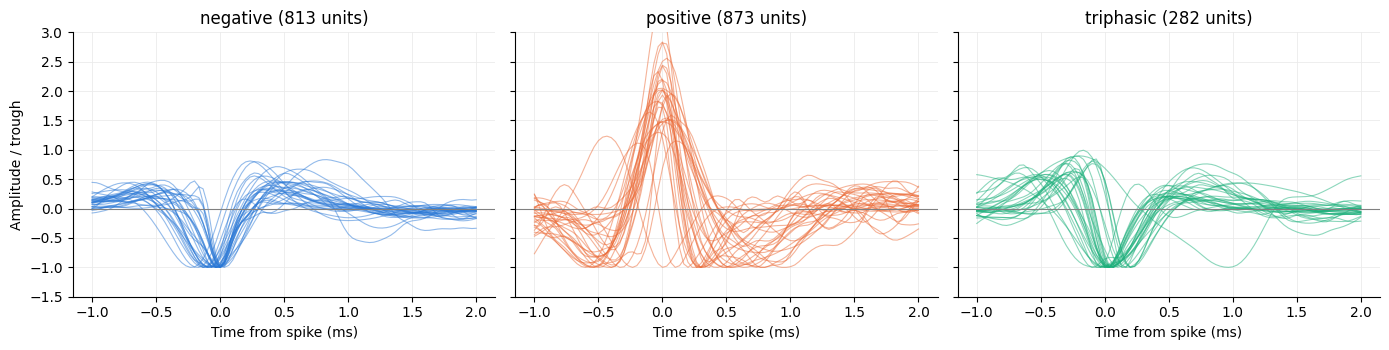

In [7]:
t_ms = z['waveform_ms']
wf = z['waveforms']
peak = np.array([np.argmax(np.ptp(w, 0)) if np.isfinite(w).all() else 0 for w in wf])
w_peak = wf[np.arange(len(wf)), :, peak]
rng = np.random.default_rng(0)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (p, c) in zip(axs, POLARITY_COLORS.items()):
    idx = np.flatnonzero(d['polarity'] == p)
    for i in rng.choice(idx, min(30, idx.size), replace=False):
        ax.plot(t_ms, w_peak[i] / -w_peak[i].min(), color=c, lw=0.8, alpha=0.5)
    ax.axhline(0, color='0.5', lw=0.8)
    ax.set(title=f'{p} ({idx.size} units)', xlabel='Time from spike (ms)', ylim=(-1.5, 3))
axs[0].set_ylabel('Amplitude / trough')
fig.tight_layout()

### Why polarity only makes a unit ambiguous

The spec would exclude every positive or positive-leading unit, which is 58% of OB units. Checks made while setting up
the screen argue against reading these as axons or dendrites:

- **CA1 too:** on the same recordings, about 40% of CA1 templates (Kilosort, unwhitened) are positive-dominant in
  every mouse, and they can't plausibly all be axons.
- **Not the wiring:** positive units are as local to their tetrode as negative ones (the largest other tetrode is about
  0.17 of the peak for both), so they aren't a reference-wire artifact. They share wires with negative units in every
  mouse, so they aren't inverted channels.
- **Same physiology:** in OB they match the negative units on M/T type, sniff-locking and isolation (below).

Why the recordings split into two polarity groups is still open. Until it's settled, main results use negative units,
and the sensitivity set adds the positive ones back.

mt_cell_type  mitral  other  tufted
polarity                           
negative        0.29   0.33    0.38
positive        0.26   0.36    0.38
triphasic       0.44   0.35    0.21

             snr  isi_violation  isolation_distance  trough_to_peak_ms  sniff_peak_ms  burst_frac
polarity                                                                                         
negative   2.679          0.034              29.068              0.467           85.0       0.227
positive   2.284          0.028              28.506              0.800           85.0       0.183
triphasic  2.441          0.031              27.648              0.617          105.0       0.198


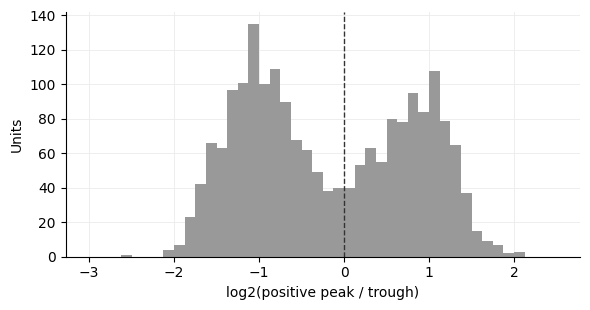

In [8]:
print(pd.crosstab(d['polarity'], d['mt_cell_type'], normalize='index').round(2).to_string())
print()
print(d.groupby('polarity')[['snr', 'isi_violation', 'isolation_distance', 'trough_to_peak_ms', 'sniff_peak_ms',
                             'burst_frac']].median().round(3).to_string())
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(np.log2(d['pos_ratio']), np.linspace(-3, 2.5, 45), color='0.6')
ax.axvline(np.log2(wv['max_positive_ratio']), color='0.2', ls='--', lw=1)
ax.set(xlabel='log2(positive peak / trough)', ylabel='Units')
fig.tight_layout()

## Footprint and amplitude

A wire counts toward the footprint when its peak-to-peak amplitude is at least 30% of the peak wire's. A unit seen on
one wire only, with SNR below 1.5, is `confined_small`. SNR is peak-to-peak amplitude over the robust SD of the
bandpassed signal on that wire. That SD includes the background of other OB spikes (about 30 uV), so SNR is low
(median 2.5). The SNR cutoffs (1.5 for small, 2 for the reference) were set after a first run with the usual 5 and 8
had shown this; they still don't depend on any tuning.

       noise_uv  ptp_uv  snr
mouse                       
9000       60.4   274.5  4.6
9002       18.1    60.2  4.0
9003       20.6    50.7  2.5
9005       28.5    64.0  2.3
9006       47.2    64.2  1.8
9007       30.0    56.9  2.0
9008       33.9    59.1  2.0
9009       39.3   112.1  3.1


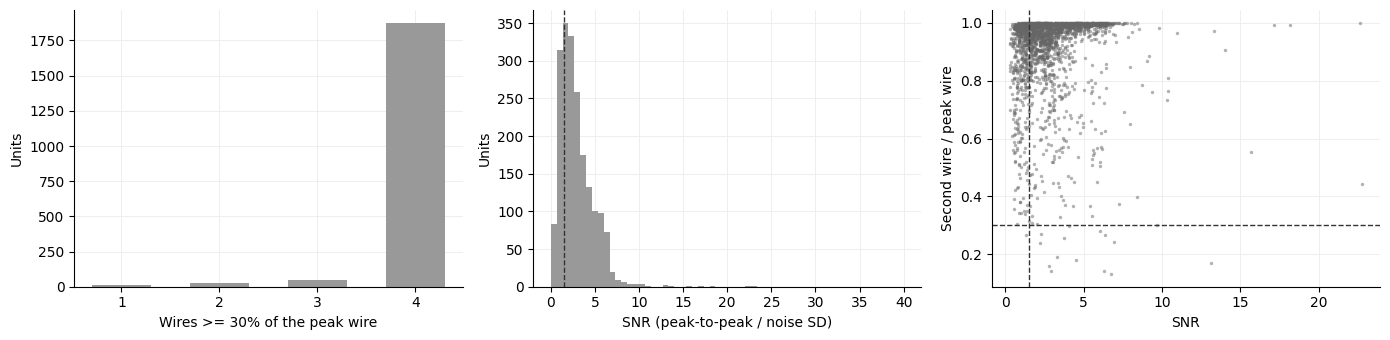

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
fp = d['footprint_n'].value_counts().reindex([1, 2, 3, 4]).fillna(0)
axs[0].bar(fp.index, fp.to_numpy(), color='0.6', width=0.6)
axs[0].set(xlabel='Wires >= 30% of the peak wire', ylabel='Units', xticks=[1, 2, 3, 4])
axs[1].hist(d['snr'].dropna().clip(0, 40), np.linspace(0, 40, 61), color='0.6')
axs[1].axvline(wv['small_snr'], color='0.2', ls='--', lw=1)
axs[1].set(xlabel='SNR (peak-to-peak / noise SD)', ylabel='Units')
axs[2].scatter(d['snr'].clip(0, 40), d['second_wire_ratio'], s=6, c='0.4', alpha=0.5, lw=0)
axs[2].axhline(wv['footprint_wire_frac'], color='0.2', ls='--', lw=1)
axs[2].axvline(wv['small_snr'], color='0.2', ls='--', lw=1)
axs[2].set(xlabel='SNR', ylabel='Second wire / peak wire')
fig.tight_layout()
print(d.groupby('mouse')[['noise_uv', 'ptp_uv', 'snr']].median().round(1))

### Tetrodes whose wires look the same

39% of units have nearly the same spike on all four wires: the smallest wire is at least 90% of the largest, and every
wire is correlated at 0.98 or more with the peak wire (`uniform_wires`). These spikes are still local to their tetrode,
so they aren't noise shared by all tetrodes. It's a property of particular tetrodes, and it holds across sessions:
the table below is the median ratio of the smallest wire to the largest. It looks as if those tetrodes' wires are
bridged. There a unit can't be localized by its footprint, and isolation suffers. This is reported only, because it
doesn't say whether a unit is a cell body.

In [10]:
print(d.pivot_table(index='mouse', columns='tetrode', values='min_wire_ratio', aggfunc='median').round(2).to_string())
print()
print(f"uniform_wires: {d['fail_uniform_wires'].sum()} units ({d['fail_uniform_wires'].mean():.0%})")

tetrode     0     1     2     3
mouse                          
9000     0.82  0.48  0.85  0.97
9002     0.98  0.73  0.35  0.98
9003     0.71  0.69  0.77  0.75
9005     0.72  0.58  0.67  0.86
9006     0.95  0.92  0.87  0.79
9007     0.83  0.67  0.54  0.70
9008     0.90  0.90  0.66  0.90
9009     0.48  0.94  0.78  0.73

uniform_wires: 761 units (39%)


## Stage B: glomerular-layer signatures

### LFP per tetrode

The spec expects gamma (40-100 Hz) to be strongest near the EPL / MCL, and the sniff-evoked slow potential to change
polarity from GL to EPL. Without depth, each tetrode-session is compared with the rest of its mouse instead. A
tetrode-session counts as `lfp_gl_like` when its sniff-triggered LFP is reversed against the mouse's median one
(Pearson r < 0 over 0-300 ms after inhalation), *and* its relative gamma power is in the mouse's lowest quartile. Its
units become ambiguous. Line-noise bands are left out of the power.

A first version compared the sign of the mean 0-200 ms potential instead. That window straddles a peak and a trough,
so it flagged tetrodes whose waveform had the same shape as the rest; the shape correlation replaced it.

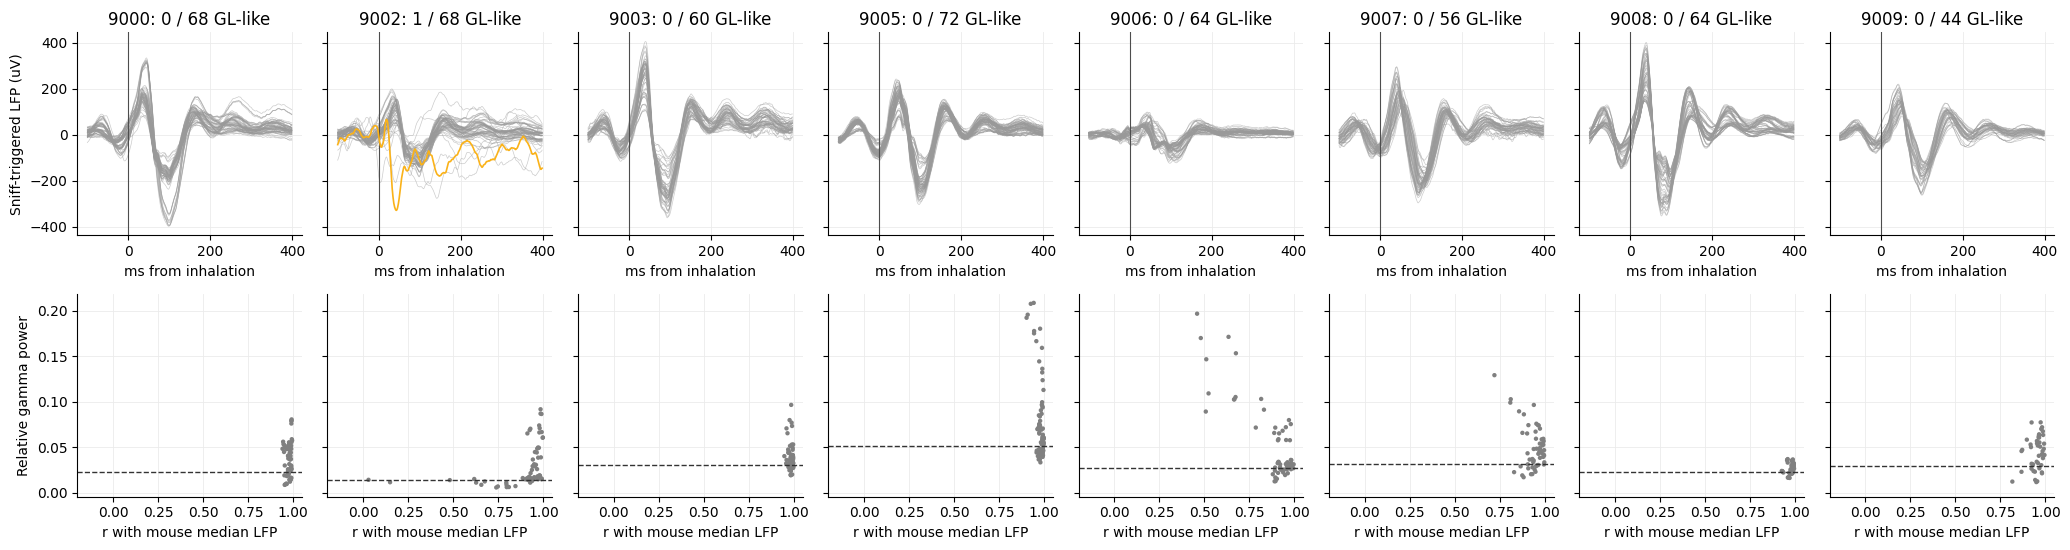

In [11]:
mice = sorted(lfp['mouse'].unique())
fig, axs = plt.subplots(2, len(mice), figsize=(2.6 * len(mice), 5.6), sharey='row')
for j, m in enumerate(mice):
    s = (z['lfp_mouse'] == m)
    gl_like = lfp.loc[s, 'lfp_gl_like'].to_numpy()
    for k in np.flatnonzero(s):
        bad = lfp.loc[k, 'lfp_gl_like']
        axs[0, j].plot(z['sta_ms'], z['sta'][k], color=LABEL_COLORS['ambiguous'] if bad else '0.6',
                       lw=1.2 if bad else 0.5, alpha=1 if bad else 0.5, zorder=3 if bad else 1)
    axs[0, j].axvline(0, color='0.3', lw=0.8)
    axs[0, j].set(title=f'{m}: {gl_like.sum()} / {s.sum()} GL-like', xlabel='ms from inhalation')
    dm = lfp[lfp['mouse'] == m]
    axs[1, j].scatter(dm['sta_r'], dm['rel_gamma'], s=10, lw=0,
                      c=np.where(dm['lfp_gl_like'], LABEL_COLORS['ambiguous'], '0.5'))
    axs[1, j].axhline(dm['rel_gamma'].quantile(cfg['lfp']['low_gamma_quantile']), color='0.2', ls='--', lw=1)
    axs[1, j].set(xlabel='r with mouse median LFP', xlim=(-0.2, 1.05))
axs[0, 0].set_ylabel('Sniff-triggered LFP (uV)')
axs[1, 0].set_ylabel('Relative gamma power')
fig.tight_layout()

Every tetrode's sniff-triggered LFP has much the same shape as its mouse's median one; only one tetrode-session
(in 9002) is reversed. So with these recordings the LFP doesn't separate GL from deeper layers. It may be that the
tetrodes all sit below the GL, or that the raw LFP, against a common reference, is dominated by a volume-conducted
sniff potential. Depth from histology is what would tell these apart.

In [12]:
print(lfp['sta_r'].describe().round(3).to_string())
print(lfp.groupby('mouse')[['sta_reversed', 'low_gamma', 'lfp_gl_like']].sum().to_string())

count    496.000
mean       0.944
std        0.109
min       -0.273
25%        0.947
50%        0.974
75%        0.987
max        0.998
       sta_reversed  low_gamma  lfp_gl_like
mouse                                      
9000              0         17            0
9002              1         17            1
9003              0         15            0
9005              0         18            0
9006              0         16            0
9007              0         14            0
9008              0         16            0
9009              0         11            0


### Units: OSN terminals and juxtaglomerular cells

- **OSN terminal:** an axonal waveform, a sniff peak at or before 80 ms (p < 0.05 against random onsets), and no
  sniff-locked dip (p_dip >= 0.05), since OSN terminals are only excited. Early firing alone never excludes a unit.
- **Juxtaglomerular:** SNR < 1.5 with more than 30% of ISIs under 10 ms.

The sniff histogram covers 0-300 ms after inhalation onset, from sniffs 300-500 ms long, like the M/T classifier's
input.

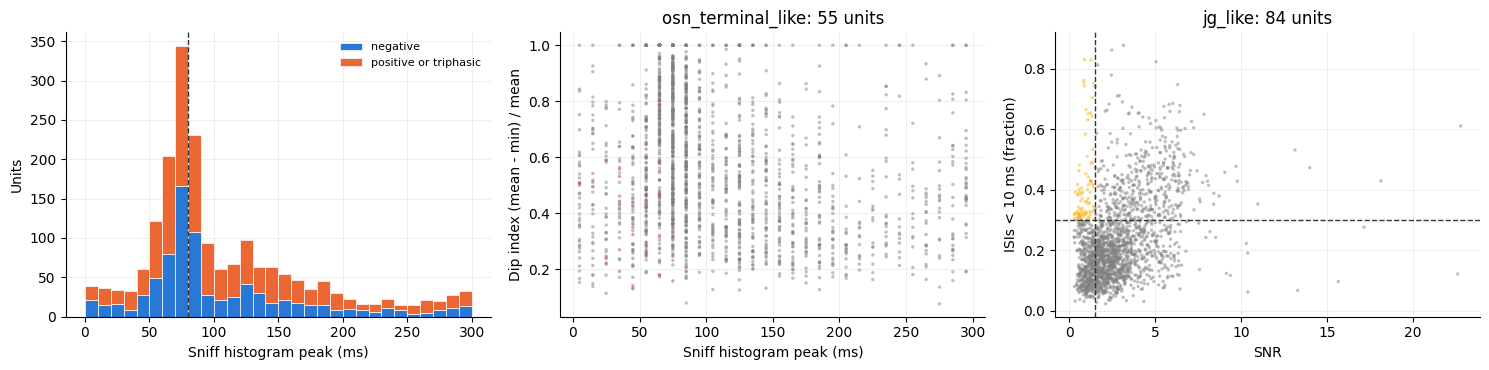

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
early = (d['sniff_peak_ms'] <= gl['early_peak_ms']) & (d['p_excite'] < gl['alpha'])
axon = d['polarity'].isin(['positive', 'triphasic'])
ax = axs[0]
bins = np.arange(0, gl['hist_window_ms'] + 1, 10)
ax.hist([d.loc[~axon & d['polarity'].notna(), 'sniff_peak_ms'], d.loc[axon, 'sniff_peak_ms']], bins, stacked=True,
        color=[POLARITY_COLORS['negative'], POLARITY_COLORS['positive']], label=['negative', 'positive or triphasic'],
        edgecolor='white', lw=0.5)
ax.axvline(gl['early_peak_ms'], color='0.2', ls='--', lw=1)
ax.set(xlabel='Sniff histogram peak (ms)', ylabel='Units')
ax.legend(frameon=False, fontsize=8)

ax = axs[1]
ax.scatter(d['sniff_peak_ms'], d['dip_index'], s=6, lw=0, alpha=0.5,
           c=np.where(d['fail_osn_terminal_like'], LABEL_COLORS['exclude'], '0.5'))
ax.set(xlabel='Sniff histogram peak (ms)', ylabel='Dip index (mean - min) / mean',
       title=f"osn_terminal_like: {d['fail_osn_terminal_like'].sum()} units")

ax = axs[2]
ax.scatter(d['snr'].clip(0, 40), d['burst_frac'], s=6, lw=0, alpha=0.5,
           c=np.where(d['fail_jg_like'], LABEL_COLORS['ambiguous'], '0.5'))
ax.axvline(wv['small_snr'], color='0.2', ls='--', lw=1)
ax.axhline(gl['max_burst_frac'], color='0.2', ls='--', lw=1)
ax.set(xlabel='SNR', ylabel='ISIs < 10 ms (fraction)', title=f"jg_like: {d['fail_jg_like'].sum()} units")
fig.tight_layout()

## The screen and the M/T labels

The screen must not quietly remove one cell type, so here are the labels by M/T type, pooled and then within mouse
(mice contribute different mixes of types). Early firing is the main worry: the right panel checks that units peaking
early in the sniff aren't excluded more often than the rest.

In [14]:
print(pd.crosstab(d['mt_cell_type'], d['screen_label'], margins=True)[LABELS + ['All']].to_string())
t = (d.groupby(['mouse', 'mt_cell_type'])['screen_label'].apply(lambda s: (s == 'include').mean())
     .unstack()[['tufted', 'mitral', 'other']])
n = d.groupby(['mouse', 'mt_cell_type']).size().unstack()[['tufted', 'mitral', 'other']]
print('\nFraction include, within mouse (n units in brackets)')
print(t.round(2).astype(str) + ' (' + n.fillna(0).astype(int).astype(str) + ')')
both = t[['tufted', 'mitral']].dropna()
both = both[(n.loc[both.index, ['tufted', 'mitral']] >= 5).all(1)]
if len(both) >= 2:
    w = stats.wilcoxon(both['tufted'], both['mitral'])
    print(f"\ntufted vs mitral include fraction, {len(both)} mice with >= 5 of each: "
          f"tufted higher in {(both['tufted'] > both['mitral']).sum()}, Wilcoxon p = {w.pvalue:.3f}")

screen_label  include  ambiguous  exclude   All
mt_cell_type                                   
mitral            219        335       29   583
other             246        424        8   678
tufted            311        377       19   707
All               776       1136       56  1968

Fraction include, within mouse (n units in brackets)
mt_cell_type      tufted     mitral       other
mouse                                          
9000           0.37 (46)  0.35 (97)   0.53 (96)
9002           0.31 (13)   0.4 (84)  0.37 (132)
9003          0.37 (107)   0.4 (10)   0.47 (53)
9005          0.39 (139)  0.31 (89)   0.38 (52)
9006           0.49 (53)  0.3 (191)  0.22 (215)
9007           0.52 (71)  0.45 (11)   0.31 (52)
9008          0.38 (111)  0.53 (90)   0.49 (65)
9009          0.54 (167)  0.73 (11)   0.46 (13)

tufted vs mitral include fraction, 8 mice with >= 5 of each: tufted higher in 4, Wilcoxon p = 0.844


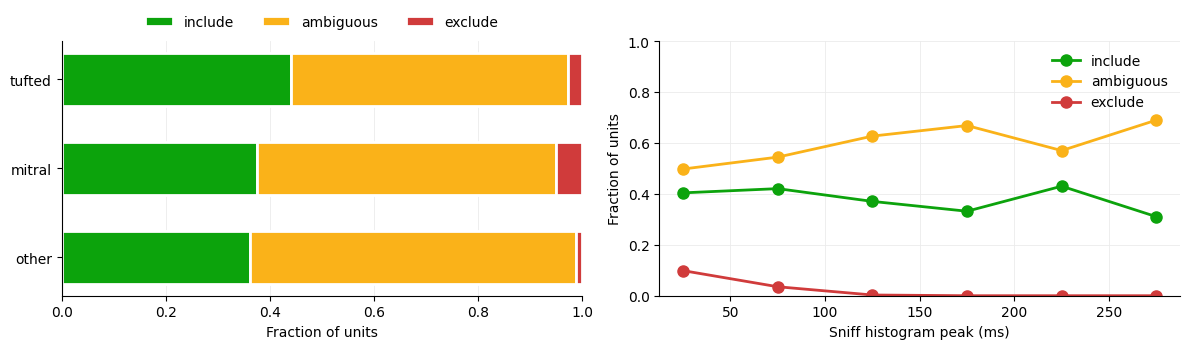

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
t = pd.crosstab(d['mt_cell_type'], d['screen_label'], normalize='index').reindex(['tufted', 'mitral', 'other'])[LABELS]
left = np.zeros(len(t))
for lab in LABELS:
    axs[0].barh(t.index, t[lab], left=left, color=LABEL_COLORS[lab], label=lab, height=0.6, edgecolor='white', lw=2)
    left += t[lab].to_numpy()
axs[0].set(xlabel='Fraction of units', xlim=(0, 1))
axs[0].invert_yaxis()
axs[0].grid(axis='y', visible=False)
axs[0].legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1))

edges = np.arange(0, gl['hist_window_ms'] + 1, 50)
cut = pd.cut(d['sniff_peak_ms'], edges)
f = d.groupby(cut, observed=False)['screen_label'].value_counts(normalize=True).unstack().reindex(columns=LABELS)
x = edges[:-1] + 25
for lab in LABELS:
    axs[1].plot(x, f[lab], marker='o', ms=8, lw=2, color=LABEL_COLORS[lab], label=lab)
axs[1].set(xlabel='Sniff histogram peak (ms)', ylabel='Fraction of units', ylim=(0, 1))
axs[1].legend(frameon=False)
fig.tight_layout()

## Example units

For each screening outcome, the mean waveforms on the four wires (peak wire in black) and the sniff histogram.

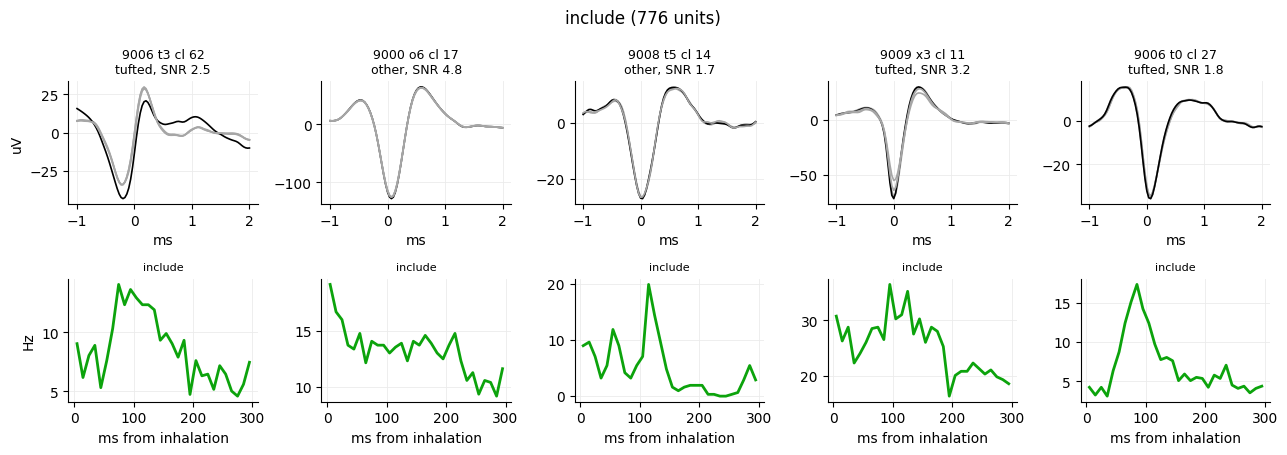

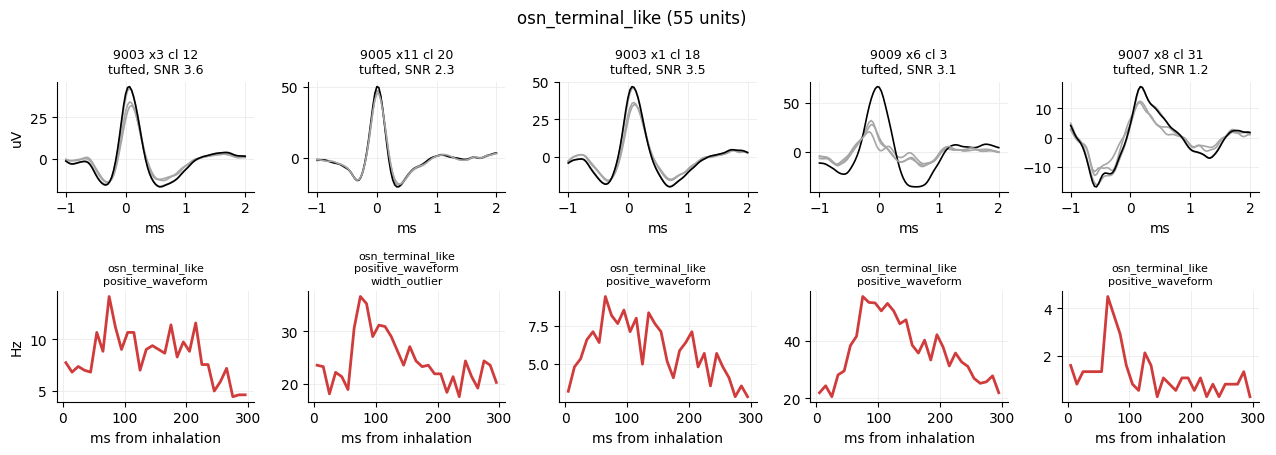

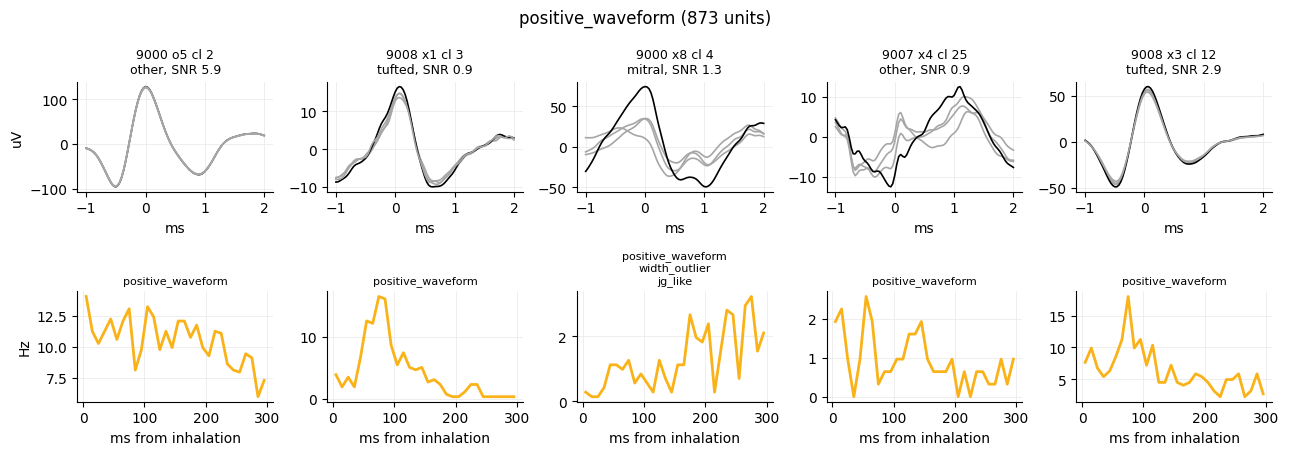

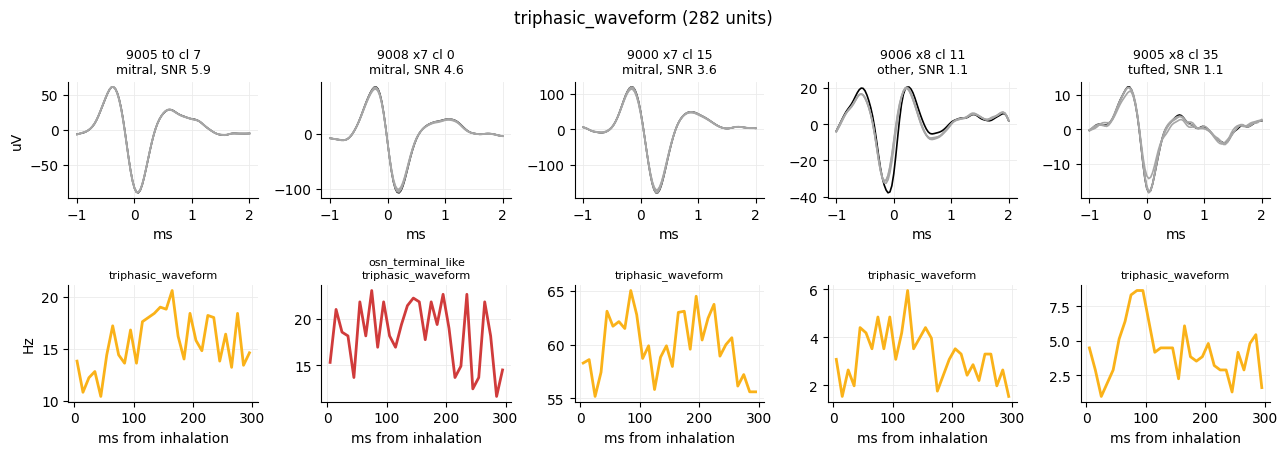

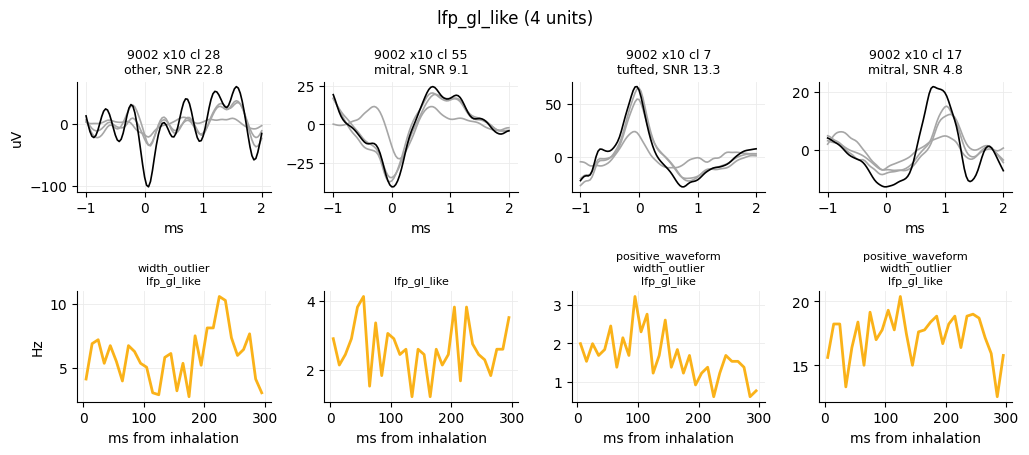

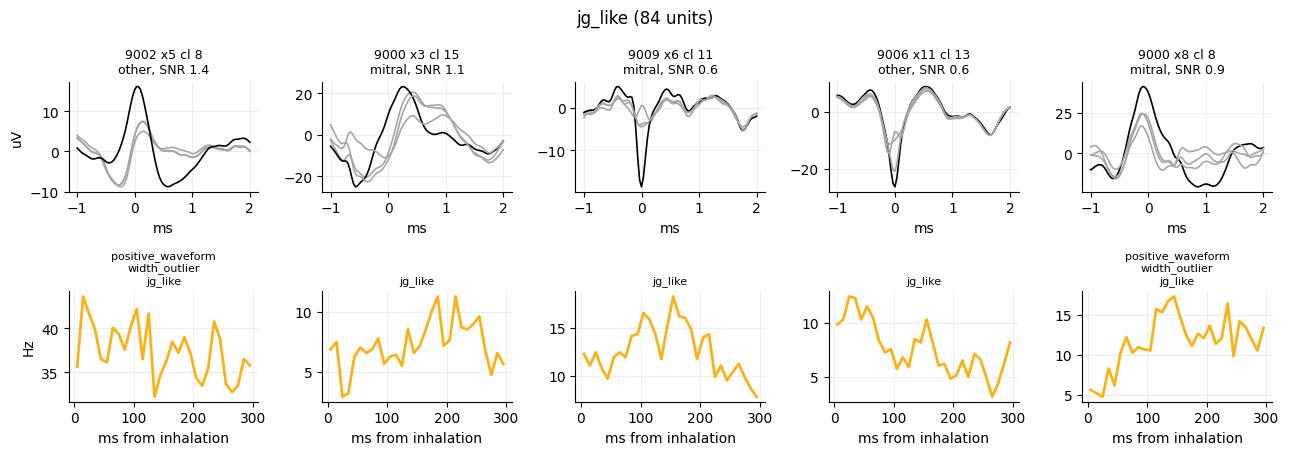

In [16]:
def show(rows, title):
    fig, axs = plt.subplots(2, len(rows), figsize=(2.6 * len(rows), 4.6), squeeze=False)
    for j, i in enumerate(rows):
        u = d.loc[i]
        w = wf[i]
        for k in range(w.shape[1]):
            axs[0, j].plot(t_ms, w[:, k], color='k' if k == np.argmax(np.ptp(w, 0)) else '0.65', lw=1.2)
        axs[0, j].set_title(f"{u.mouse} {u.session} cl {u.cluster}\n{u.mt_cell_type}, SNR {u.snr:.1f}", fontsize=9)
        axs[0, j].set_xlabel('ms')
        axs[1, j].plot(z['hist_ms'], z['hist'][i], color=LABEL_COLORS[u.screen_label], lw=2)
        axs[1, j].set_xlabel('ms from inhalation')
        axs[1, j].set_title(u.screen_reason.replace(';', '\n') or 'include', fontsize=8)
    axs[0, 0].set_ylabel('uV')
    axs[1, 0].set_ylabel('Hz')
    fig.suptitle(title)
    fig.tight_layout()

rng = np.random.default_rng(1)
for name, mask in [('include', d['screen_label'] == 'include'),
                   ('osn_terminal_like', d['fail_osn_terminal_like']),
                   ('positive_waveform', d['fail_positive_waveform']),
                   ('triphasic_waveform', d['fail_triphasic_waveform']),
                   ('lfp_gl_like', d['fail_lfp_gl_like']),
                   ('jg_like', d['fail_jg_like'])]:
    idx = np.flatnonzero(mask & np.isfinite(wf).all((1, 2)))
    if idx.size:
        show(rng.choice(idx, min(5, idx.size), replace=False), f'{name} ({idx.size} units)')

## Using the labels

```python
scr = pd.read_csv('E:/cbm-odor/sniff/unit_screening.csv', dtype={'mouse': str, 'session': str})
keep = scr.loc[scr['screen_label'] == 'include', ['mouse', 'session', 'cluster']]            # main results
keep_sens = scr.loc[scr['screen_label'] != 'exclude', ['mouse', 'session', 'cluster']]       # sensitivity
```

Merge on `mouse, session, cluster` (OB only). To change a threshold, edit `ob_screening_config.json` and run
`python ob_screening.py --relabel`. That redoes the labels from the saved metrics in a few seconds, without reading
the raw data again.